# Final Model Fitting and Evaluation

## 1. Objective and Evaluation Strategy

This notebook completes the multiclass prediction of **Home Win**, **Draw**, and **Away Win** outcomes using the 40 features selected in the previous modelling notebook.

The data split is chronological: training seasons are used to fit each candidate, the validation season is used for model selection, and the 2015/2016 test season is evaluated once only after the final model has been selected. **Macro F1** is the primary metric because all three outcomes matter; accuracy is retained as a secondary measure.

## 2. Imports and Project Paths

Imports are consolidated here, and repository-relative paths are resolved whether Jupyter starts from the project root or a notebook directory.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
CLASS_ORDER = ["Home Win", "Draw", "Away Win"]

## 3. Load and Validate Modelling Data

The processed splits were created chronologically upstream: training covers 2010/2011–2013/2014, validation covers 2014/2015, and test covers 2015/2016. This section checks their schemas and completeness without using test performance for any decision.

In [2]:
split_files = {
    "Training (2010/11–2013/14)": "train_processed.csv",
    "Validation (2014/15)": "validation_processed.csv",
    "Test (2015/16)": "test_processed.csv",
}
split_data = {
    split_name: pd.read_csv(PROCESSED_DIR / filename)
    for split_name, filename in split_files.items()
}
train_data = split_data["Training (2010/11–2013/14)"]
validation_data = split_data["Validation (2014/15)"]
test_data = split_data["Test (2015/16)"]

for split_name, data in split_data.items():
    assert "target" in data.columns, f"target is missing from {split_name}"
    assert data["target"].notna().all(), f"Missing target values in {split_name}"
    assert set(data["target"].unique()) == set(CLASS_ORDER)

predictor_columns = train_data.columns.drop("target")
assert validation_data.columns.equals(train_data.columns)
assert test_data.columns.equals(train_data.columns)
assert "target" not in predictor_columns

split_summary = pd.DataFrame([
    {
        "split": split_name,
        "matches": len(data),
        "predictors": len(predictor_columns),
        "missing_predictor_values": int(data[predictor_columns].isna().sum().sum()),
        "missing_targets": int(data["target"].isna().sum()),
    }
    for split_name, data in split_data.items()
])
display(split_summary)

class_distribution = pd.concat(
    {
        "Training": train_data["target"].value_counts(normalize=True).reindex(CLASS_ORDER),
        "Validation": validation_data["target"].value_counts(normalize=True).reindex(CLASS_ORDER),
    },
    axis=1,
).mul(100).round(2)
class_distribution.index.name = "outcome"
display(class_distribution.rename(columns=lambda name: f"{name} percent"))

assert split_summary["missing_predictor_values"].sum() == 0
assert np.isfinite(train_data[predictor_columns].to_numpy()).all()
assert np.isfinite(validation_data[predictor_columns].to_numpy()).all()
assert np.isfinite(test_data[predictor_columns].to_numpy()).all()

,split,matches,predictors,missing_predictor_values,missing_targets
0,Training (2010/11–2013/14),11413,80,0,0
1,Validation (2014/15),3067,80,0,0
2,Test (2015/16),3129,80,0,0


,Training percent,Validation percent
outcome,,
Home Win,46.21,44.80
Draw,25.13,25.66
Away Win,28.66,29.54


### Finding

The three chronological splits have aligned columns, 80 numeric predictors, complete targets, and no missing or non-finite predictor values. Training and validation both contain all three outcomes and are ready for final model comparison.

## 4. Load the Selected Features

Feature selection was completed using the training and validation workflow in the previous notebook. It is not repeated here; the saved Top-40 order is treated as the modelling contract for every final candidate.

In [3]:
feature_path = TABLES_DIR / "selected_top40_features.csv"
selected_features = pd.read_csv(feature_path)["feature"].tolist()

assert len(selected_features) == 40
assert len(selected_features) == len(set(selected_features))
for split_name, data in split_data.items():
    missing_features = sorted(set(selected_features) - set(data.columns))
    assert not missing_features, f"Selected features missing from {split_name}: {missing_features}"

X_train_selected = train_data.loc[:, selected_features].copy()
X_val_selected = validation_data.loc[:, selected_features].copy()
X_test_selected = test_data.loc[:, selected_features].copy()
y_train = train_data["target"].copy()
y_val = validation_data["target"].copy()
y_test = test_data["target"].copy()

feature_check = pd.DataFrame({
    "split": ["Training", "Validation", "Test"],
    "rows": [len(X_train_selected), len(X_val_selected), len(X_test_selected)],
    "selected_features": [
        X_train_selected.shape[1], X_val_selected.shape[1], X_test_selected.shape[1]
    ],
})
display(feature_check)
display(pd.DataFrame({"feature_order": range(1, 41), "feature": selected_features}))

,split,rows,selected_features
0,Training,11413,40
1,Validation,3067,40
2,Test,3129,40


,feature_order,feature
0,1,overall_rating_diff
1,2,potential_diff
2,3,passing_diff
3,4,technical_diff
4,5,attack_diff
5,6,pace_diff
6,7,physical_diff
7,8,home_avg_technical
8,9,defence_diff
9,10,goalkeeper_diff


### Finding

All 40 selected features are available in the same deterministic order across training, validation, and test data. Relative team-strength variables lead the saved ranking.

## 5. Prepare Training and Validation Data

Only Linear SVM requires standardized inputs. `StandardScaler` is fitted on training data and applied unchanged to validation data. Tree-based candidates use the unscaled Top-40 matrices.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_val_scaled = scaler.transform(X_val_selected)

scaling_check = pd.DataFrame({
    "training_mean": X_train_scaled.mean(axis=0),
    "training_population_std": X_train_scaled.std(axis=0),
}, index=selected_features)
display(scaling_check.round(6))

assert np.allclose(scaling_check["training_mean"], 0, atol=1e-10)
assert np.allclose(scaling_check["training_population_std"], 1, atol=1e-10)

,training_mean,training_population_std
overall_rating_diff,0.0,1.0
potential_diff,-0.0,1.0
passing_diff,0.0,1.0
technical_diff,-0.0,1.0
attack_diff,0.0,1.0
pace_diff,0.0,1.0
physical_diff,0.0,1.0
home_avg_technical,-0.0,1.0
defence_diff,0.0,1.0
goalkeeper_diff,-0.0,1.0


## 6. Final Candidate Model Comparison

These five candidates and their fixed configurations come from the completed project experiments. No hyperparameter search is performed here. Every candidate is fitted on training data and evaluated on validation data using the same class order and metrics.

In [5]:
validation_results = []
validation_reports = {}


def record_validation_result(model_name, predictions):
    validation_results.append({
        "model": model_name,
        "validation_accuracy": accuracy_score(y_val, predictions),
        "validation_macro_f1": f1_score(y_val, predictions, average="macro"),
    })
    validation_reports[model_name] = pd.DataFrame(
        classification_report(
            y_val,
            predictions,
            labels=CLASS_ORDER,
            output_dict=True,
            zero_division=0,
        )
    ).T


linear_svm = LinearSVC(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    max_iter=10_000,
)
linear_svm.fit(X_train_scaled, y_train)
svm_predictions = linear_svm.predict(X_val_scaled)
record_validation_result("Linear SVM", svm_predictions)

display(validation_reports["Linear SVM"].round(3))

,precision,recall,f1-score,support
Home Win,0.552,0.721,0.625,1374.0
Draw,0.202,0.028,0.049,787.0
Away Win,0.447,0.574,0.503,906.0
accuracy,0.500,0.500,0.500,0.5
macro avg,0.400,0.441,0.392,3067.0
weighted avg,0.431,0.500,0.441,3067.0


### Linear SVM Finding

Linear SVM has reasonable overall accuracy but very weak Draw recall. Its lower Macro F1 makes it less suitable than candidates that distribute performance more evenly across the three outcomes.

,precision,recall,f1-score,support
Home Win,0.520,0.859,0.647,1374.000
Draw,0.244,0.014,0.026,787.000
Away Win,0.519,0.430,0.471,906.000
accuracy,0.515,0.515,0.515,0.515
macro avg,0.428,0.434,0.382,3067.000
weighted avg,0.449,0.515,0.436,3067.000


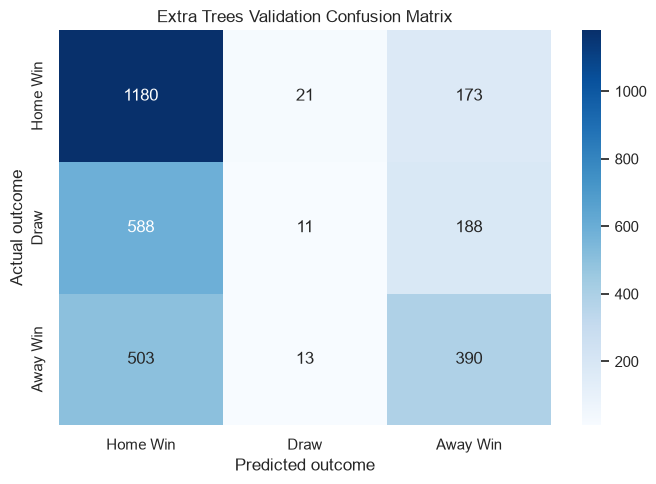

In [6]:
extra_trees = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
extra_trees.fit(X_train_selected, y_train)
extra_predictions = extra_trees.predict(X_val_selected)
record_validation_result("Extra Trees", extra_predictions)

display(validation_reports["Extra Trees"].round(3))

extra_confusion = confusion_matrix(y_val, extra_predictions, labels=CLASS_ORDER)
plt.figure(figsize=(7, 5))
sns.heatmap(
    extra_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
)
plt.title("Extra Trees Validation Confusion Matrix")
plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "extra_trees_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Extra Trees Finding

Extra Trees records the highest raw validation accuracy among the candidates but identifies almost no Draws. The resulting low Macro F1 demonstrates why accuracy is not the primary selection metric for this task.

In [7]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded,
)
xgboost_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgboost_model.fit(
    X_train_selected,
    y_train_encoded,
    sample_weight=xgb_sample_weights,
)
xgb_predictions = label_encoder.inverse_transform(
    xgboost_model.predict(X_val_selected).astype(int)
)
record_validation_result("XGBoost", xgb_predictions)

balanced_train_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train,
)
hist_gradient_boosting = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=200,
    max_leaf_nodes=15,
    random_state=RANDOM_STATE,
)
hist_gradient_boosting.fit(
    X_train_selected,
    y_train,
    sample_weight=balanced_train_weights,
)
hist_predictions = hist_gradient_boosting.predict(X_val_selected)
record_validation_result("HistGradientBoosting", hist_predictions)

gradient_boosting = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE,
)
gradient_boosting.fit(
    X_train_selected,
    y_train,
    sample_weight=balanced_train_weights,
)
gradient_predictions = gradient_boosting.predict(X_val_selected)
record_validation_result("Gradient Boosting", gradient_predictions)

boosting_report = pd.concat(
    {
        model_name: validation_reports[model_name].loc[CLASS_ORDER, ["precision", "recall", "f1-score"]]
        for model_name in ["XGBoost", "HistGradientBoosting", "Gradient Boosting"]
    },
    names=["model", "outcome"],
)
display(boosting_report.round(3))

precision  recall  f1-score
model                outcome                              
XGBoost              Home Win      0.603   0.546     0.573
                     Draw          0.271   0.294     0.282
                     Away Win      0.468   0.501     0.484
HistGradientBoosting Home Win      0.603   0.544     0.572
                     Draw          0.291   0.310     0.300
                     Away Win      0.467   0.509     0.487
Gradient Boosting    Home Win      0.618   0.549     0.581
                     Draw          0.284   0.323     0.302
                     Away Win      0.476   0.500     0.488

### Boosting Finding

The balanced boosting candidates recover substantially more Draws than Linear SVM or Extra Trees. Gradient Boosting provides the strongest validation Macro F1 in the established comparison while retaining competitive accuracy.

In [8]:
validation_comparison = (
    pd.DataFrame(validation_results)
    .sort_values(
        ["validation_macro_f1", "validation_accuracy"],
        ascending=False,
    )
    .reset_index(drop=True)
)
validation_comparison.insert(0, "rank", range(1, len(validation_comparison) + 1))
display(validation_comparison.round(4))

,rank,model,validation_accuracy,validation_macro_f1
0,1,Gradient Boosting,0.4764,0.4570
1,2,HistGradientBoosting,0.4738,0.4531
2,3,XGBoost,0.4679,0.4462
3,4,Linear SVM,0.4995,0.3922
4,5,Extra Trees,0.5155,0.3815


## 7. Final Model Selection

The final model is selected programmatically from validation Macro F1. Test predictions have not been generated or evaluated at this point.

In [9]:
selected_model_name = validation_comparison.loc[0, "model"]
selected_validation_macro_f1 = validation_comparison.loc[0, "validation_macro_f1"]
selected_validation_accuracy = validation_comparison.loc[0, "validation_accuracy"]

assert selected_model_name == "Gradient Boosting"
display(Markdown(
    f"### Decision\n\n"
    f"**{selected_model_name}** is selected with validation Macro F1 "
    f"**{selected_validation_macro_f1:.4f}** and accuracy "
    f"**{selected_validation_accuracy:.4f}**. It leads the primary metric "
    "and provides better balance across outcomes than the higher-accuracy Extra Trees model."
))

### Decision

**Gradient Boosting** is selected with validation Macro F1 **0.4570** and accuracy **0.4764**. It leads the primary metric and provides better balance across outcomes than the higher-accuracy Extra Trees model.

## 8. Final Test Evaluation

With the model choice fixed, the selected configuration is retrained on the combined training and validation periods. Balanced sample weights are recalculated for that combined sample, and the untouched 2015/2016 test season is then evaluated once.

,metric,value
0,Accuracy,0.4500
1,Macro F1,0.4376


,precision,recall,f1-score,support
Home Win,0.586,0.497,0.538,1378.00
Draw,0.279,0.350,0.310,801.00
Away Win,0.463,0.466,0.465,950.00
accuracy,0.450,0.450,0.450,0.45
macro avg,0.443,0.438,0.438,3129.00
weighted avg,0.470,0.450,0.457,3129.00


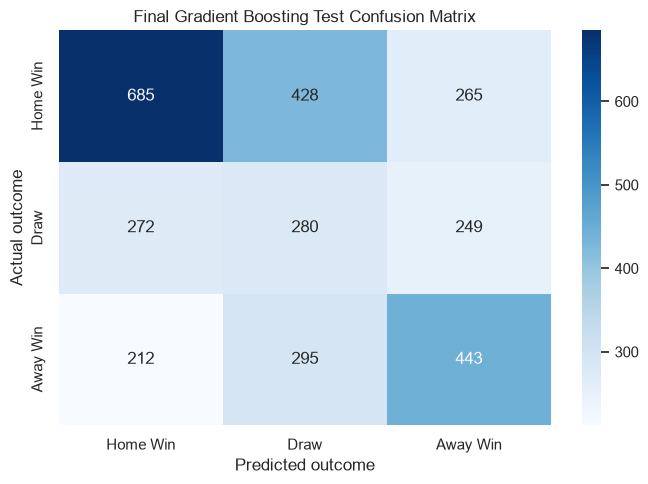

In [10]:
X_final_train = pd.concat(
    [X_train_selected, X_val_selected],
    axis=0,
    ignore_index=True,
)
y_final_train = pd.concat([y_train, y_val], axis=0, ignore_index=True)
final_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_final_train,
)

final_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE,
)
final_model.fit(
    X_final_train,
    y_final_train,
    sample_weight=final_sample_weights,
)
final_predictions = final_model.predict(X_test_selected)

test_accuracy = accuracy_score(y_test, final_predictions)
test_macro_f1 = f1_score(y_test, final_predictions, average="macro")
test_metrics = pd.DataFrame({
    "metric": ["Accuracy", "Macro F1"],
    "value": [test_accuracy, test_macro_f1],
})
test_classification_report = pd.DataFrame(
    classification_report(
        y_test,
        final_predictions,
        labels=CLASS_ORDER,
        output_dict=True,
        zero_division=0,
    )
).T

display(test_metrics.round(4))
display(test_classification_report.round(3))

final_confusion = confusion_matrix(y_test, final_predictions, labels=CLASS_ORDER)
plt.figure(figsize=(7, 5))
sns.heatmap(
    final_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
)
plt.title("Final Gradient Boosting Test Confusion Matrix")
plt.xlabel("Predicted outcome")
plt.ylabel("Actual outcome")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Interpretation

The final test result is consistent with the completed project result. Draw remains the weakest class, although balanced Gradient Boosting identifies substantially more Draws than the SVM and Extra Trees validation candidates.

## 9. Final Model Interpretation

Gradient Boosting exposes feature importances based on how often and how effectively features reduce loss across its trees. These values describe this fitted model; they do not establish causal effects.

,Feature,Importance
0,overall_rating_diff,0.439424
1,potential_diff,0.099010
2,passing_diff,0.049949
3,physical_diff,0.022282
4,home_avg_technical,0.021180
5,recent_goals_scored_diff,0.019933
6,pace_diff,0.017146
7,away_avg_technical,0.016970
8,stage,0.016263
9,home_avg_passing,0.015263


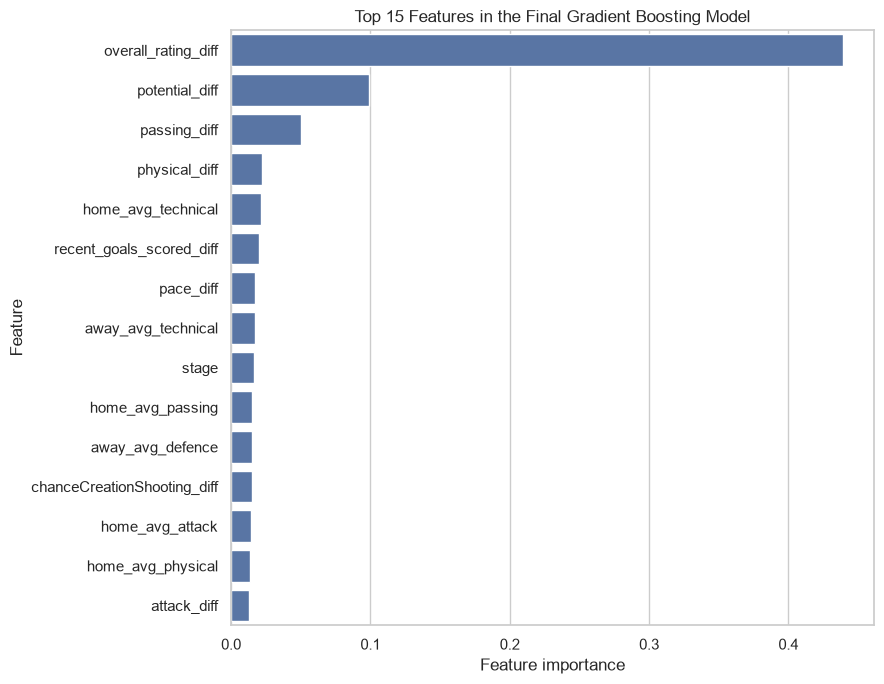

In [11]:
final_importance = (
    pd.DataFrame({
        "Feature": selected_features,
        "Importance": final_model.feature_importances_,
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
top_final_importance = final_importance.head(15)
display(top_final_importance)

plt.figure(figsize=(9, 7))
sns.barplot(
    data=top_final_importance,
    x="Importance",
    y="Feature",
    color=sns.color_palette("deep")[0],
)
plt.title("Top 15 Features in the Final Gradient Boosting Model")
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "final_model_feature_importance.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Finding

Relative team-strength variables—especially overall-rating and potential differences—are among the final model's strongest signals. This agrees with the upstream feature-selection evidence that differences between the two teams are more informative than many isolated team measurements.

## 10. Export Final Results

The final comparison, one-time test results, classification report, and fitted-model importance values are saved once. Model persistence is not introduced because it was not part of the existing primary-scope workflow.

In [12]:
validation_comparison.to_csv(
    TABLES_DIR / "final_model_validation_comparison.csv",
    index=False,
)
test_metrics.to_csv(TABLES_DIR / "final_test_metrics.csv", index=False)
test_classification_report.to_csv(
    TABLES_DIR / "final_test_classification_report.csv"
)
final_importance.to_csv(
    TABLES_DIR / "final_model_feature_importance.csv",
    index=False,
)

exported_outputs = pd.DataFrame({
    "output": [
        "outputs/tables/final_model_validation_comparison.csv",
        "outputs/tables/final_test_metrics.csv",
        "outputs/tables/final_test_classification_report.csv",
        "outputs/tables/final_model_feature_importance.csv",
        "outputs/figures/extra_trees_validation_confusion_matrix.png",
        "outputs/figures/final_test_confusion_matrix.png",
        "outputs/figures/final_model_feature_importance.png",
    ]
})
display(exported_outputs)

,output
0,outputs/tables/final_model_validation_comparis...
1,outputs/tables/final_test_metrics.csv
2,outputs/tables/final_test_classification_repor...
3,outputs/tables/final_model_feature_importance.csv
4,outputs/figures/extra_trees_validation_confusi...
5,outputs/figures/final_test_confusion_matrix.png
6,outputs/figures/final_model_feature_importance...


## 11. Limitations and Conclusion

Draw remains the hardest outcome because the available pre-match characteristics do not cleanly separate it from home or away wins. Football results also contain substantial uncertainty, and these findings are specific to the historical leagues and seasons represented in the dataset.

The model should therefore support probabilistic or analytical decision-making rather than be treated as a certain forecast for individual matches.

In [13]:
draw_test_recall = test_classification_report.loc["Draw", "recall"]
display(Markdown(
    f"### Final Conclusion\n\n"
    f"Balanced **Gradient Boosting** was selected because it achieved the strongest "
    f"validation Macro F1 among the established candidates. On the untouched test "
    f"season it achieved **{test_macro_f1:.4f} Macro F1** and "
    f"**{test_accuracy:.4f} accuracy**. Draw remained the most difficult outcome "
    f"with recall **{draw_test_recall:.3f}**, so practical use should account for "
    "uncertainty rather than relying only on the predicted class."
))

### Final Conclusion

Balanced **Gradient Boosting** was selected because it achieved the strongest validation Macro F1 among the established candidates. On the untouched test season it achieved **0.4376 Macro F1** and **0.4500 accuracy**. Draw remained the most difficult outcome with recall **0.350**, so practical use should account for uncertainty rather than relying only on the predicted class.